Explicar objetivo...

Dataset postado por fronkongames no Kaggle, ele usou a API própria da Steam para criar o arquivo.

Martin Bustos Roman. (2022). Steam Games Dataset [Dataset]. Kaggle. https://doi.org/10.34740/KAGGLE/DS/2109585

Bibliotecas

In [ ]:
%matplotlib inline
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import os

Montar drive e definir caminho do arquivo

In [ ]:
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Colab Datasets/games.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Carregar dataset
Nos usamos index_col=False para o pandas não usar a coluna AppID como index do dataset

In [ ]:
df = pd.read_csv(file_path, index_col=False)
df.head()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",...,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,0,Its not just a Maze; its a Quest! Enter the ca...,...,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


Mostrar colunas, quantidade de não nulos e seus tipos

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   AppID                       125855 non-null  int64  
 1   Name                        125854 non-null  object 
 2   Release date                125855 non-null  object 
 3   Estimated owners            125855 non-null  object 
 4   Peak CCU                    125855 non-null  int64  
 5   Required age                125855 non-null  int64  
 6   Price                       125855 non-null  float64
 7   Discount                    125855 non-null  int64  
 8   DLC count                   125855 non-null  int64  
 9   About the game              117393 non-null  object 
 10  Supported languages         125855 non-null  object 
 11  Full audio languages        125855 non-null  object 
 12  Reviews                     12181 non-null   object 
 13  Header image  

Nosso objetivo é analisar como o preço de um jogo está relacionado com suas caracteristicas, além de gerar, ao final, um modelo de predição que estipule o valor de um jogo a lançar na plataforma. Como no lançamento de um jogo não teremos dados concretos que só surgem com o tempo como "User score" e "Average playtime" precisamos nos restringir aos dados que realmente usaremos para o modelo de predição.

São eles:
* AppID
* Release date
* Required age
* Price
* Discount
* Full audio languages
* Windows
* Mac
* Linux
* Categories
* Genres
* Tags
* Estimated owners

AppID é necessário caso necessitarmos consultar a API da steam por mais informações. As colunas principais a ser usadas serão Price, Categories, Genres e Tags. Full audio languages será convertido em uma única quantidade int, o suporte a Windows, Mac e Linux também serão convertidos em uma única coluna int.

Por motivo de organização e clareza de visualização, serão deletadas as colunas não úteis ao nosso objetivo (aquelas que descrevem fatos que não temos acesso antes de publicar o jogo).

Parece que linhas mal formatadas estão causando corrupção nas colunas, os booleans de Windows, Mac, Linux estão sendo empurrados para a direita, vamos ler novamente o arquivo especificando separador e pulando linhas corruptas.

In [ ]:
df = pd.read_csv(
    file_path,
    sep=',',
    quotechar='"',
    on_bad_lines='skip',
    index_col=False
)

# Reassign the dataframe to keep the dropped columns excluded
df = df.drop(columns=["Name", "Peak CCU", "DLC count", "About the game", "Supported languages", "Reviews", "Header image", "Website", "Support url", "Support email", "Metacritic score", "Metacritic url", "User score", "Positive", "Negative", "Score rank", "Achievements", "Recommendations", "Notes", "Average playtime forever", "Average playtime two weeks", "Median playtime forever", "Median playtime two weeks", "Developers", "Publishers", "Screenshots", "Movies"])

In [ ]:
df.head(10)

,AppID,Release date,Estimated owners,Required age,Price,Discount,Full audio languages,Windows,Mac,Linux,Categories,Genres,Tags
0,2539430,"Aug 1, 2023",0 - 0,0,0.00,0,[],True,False,False,NaN,NaN,NaN
1,496350,"Jul 29, 2016",0 - 20000,0,5.24,65,[],True,False,False,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute"
2,1034400,"May 6, 2019",0 - 20000,0,4.99,0,[],True,True,False,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec..."
3,3292190,"Oct 31, 2024",0 - 20000,0,8.99,0,['Korean'],True,False,False,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN
4,3631080,"Apr 24, 2025",0 - 20000,0,4.99,0,['English'],True,False,False,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN
5,1654170,"Apr 5, 2023",0 - 20000,0,13.99,0,"['English', 'Turkish']",True,False,False,"Single-player,Tracked Controller Support,VR On...","Action,Adventure",NaN
6,1934300,"Apr 8, 2025",0 - 20000,0,35.99,10,[],True,False,False,"Single-player,Steam Workshop,Steam Cloud,Famil...","Simulation,Strategy","Simulation,Strategy,RTS,Wargame,Grand Strategy..."
7,700340,"Feb 1, 2018",0 - 20000,0,0.99,0,['English'],True,False,False,"Single-player,Full controller support,Family S...","Action,Indie",NaN
8,1157670,"May 7, 2021",0 - 20000,0,0.99,0,"['English', 'French', 'Italian', 'German', 'Sp...",True,False,False,"Single-player,Steam Achievements,Full controll...","Casual,Indie","Precision Platformer,Rhythm,Music,Difficult,Ab..."
9,1540330,"Dec 13, 2021",0 - 20000,0,0.59,0,[],True,True,True,"Single-player,Steam Achievements,Full controll...","Action,Casual,Indie,Strategy","Casual,Action,Strategy,Puzzle,Match 3,Singlepl..."


No futuro, colunas como "Estimated owners" podem ser usadas para darmos "peso" (weight) aos dados de jogos, assim favorecendo uns em detrimento de outros, como isto necessita algoritmo mais complexo, deixaremos de lado por agora.

Nota de tratamento de dados: As colunas Price e Discount não estavam separadas por virgula no cabeçalho do CSV o que está causando corrupção das outras colunas, abrimos o arquivo .csv e separamos Price, Discount e DLC count apropriadamente.

Convertendo Full audio Languages em int

In [ ]:
import ast

def count_languages(val):
    if pd.isna(val) or not isinstance(val, str):
        return 0
    try:
        parsed_list = ast.literal_eval(val)
        if isinstance(parsed_list, list):
            return len(parsed_list)
        return 0
    except (ValueError, SyntaxError):
        return 0

df["Full audio languages"] = df["Full audio languages"].apply(count_languages)
df.head(10)

,AppID,Release date,Estimated owners,Required age,Price,Discount,Full audio languages,Windows,Mac,Linux,Categories,Genres,Tags
0,2539430,"Aug 1, 2023",0 - 0,0,0.00,0,0,True,False,False,NaN,NaN,NaN
1,496350,"Jul 29, 2016",0 - 20000,0,5.24,65,0,True,False,False,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute"
2,1034400,"May 6, 2019",0 - 20000,0,4.99,0,0,True,True,False,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec..."
3,3292190,"Oct 31, 2024",0 - 20000,0,8.99,0,1,True,False,False,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN
4,3631080,"Apr 24, 2025",0 - 20000,0,4.99,0,1,True,False,False,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN
5,1654170,"Apr 5, 2023",0 - 20000,0,13.99,0,2,True,False,False,"Single-player,Tracked Controller Support,VR On...","Action,Adventure",NaN
6,1934300,"Apr 8, 2025",0 - 20000,0,35.99,10,0,True,False,False,"Single-player,Steam Workshop,Steam Cloud,Famil...","Simulation,Strategy","Simulation,Strategy,RTS,Wargame,Grand Strategy..."
7,700340,"Feb 1, 2018",0 - 20000,0,0.99,0,1,True,False,False,"Single-player,Full controller support,Family S...","Action,Indie",NaN
8,1157670,"May 7, 2021",0 - 20000,0,0.99,0,29,True,False,False,"Single-player,Steam Achievements,Full controll...","Casual,Indie","Precision Platformer,Rhythm,Music,Difficult,Ab..."
9,1540330,"Dec 13, 2021",0 - 20000,0,0.59,0,0,True,True,True,"Single-player,Steam Achievements,Full controll...","Action,Casual,Indie,Strategy","Casual,Action,Strategy,Puzzle,Match 3,Singlepl..."


In [ ]:
# Somando as colunas booleanas para obter a quantidade total de plataformas suportadas
df['Platforms count'] = df[['Windows', 'Mac', 'Linux']].astype(int).sum(axis=1)

# Removendo as colunas individuais de plataforma
df = df.drop(columns=['Windows', 'Mac', 'Linux'])

# Visualizando o resultado
display(df.head(10))

,AppID,Release date,Estimated owners,Required age,Price,Discount,Full audio languages,Categories,Genres,Tags,Platforms count
0,2539430,"Aug 1, 2023",0 - 0,0,0.00,0,0,NaN,NaN,NaN,1
1,496350,"Jul 29, 2016",0 - 20000,0,5.24,65,0,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",1
2,1034400,"May 6, 2019",0 - 20000,0,4.99,0,0,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",2
3,3292190,"Oct 31, 2024",0 - 20000,0,8.99,0,1,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,1
4,3631080,"Apr 24, 2025",0 - 20000,0,4.99,0,1,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,1
5,1654170,"Apr 5, 2023",0 - 20000,0,13.99,0,2,"Single-player,Tracked Controller Support,VR On...","Action,Adventure",NaN,1
6,1934300,"Apr 8, 2025",0 - 20000,0,35.99,10,0,"Single-player,Steam Workshop,Steam Cloud,Famil...","Simulation,Strategy","Simulation,Strategy,RTS,Wargame,Grand Strategy...",1
7,700340,"Feb 1, 2018",0 - 20000,0,0.99,0,1,"Single-player,Full controller support,Family S...","Action,Indie",NaN,1
8,1157670,"May 7, 2021",0 - 20000,0,0.99,0,29,"Single-player,Steam Achievements,Full controll...","Casual,Indie","Precision Platformer,Rhythm,Music,Difficult,Ab...",1
9,1540330,"Dec 13, 2021",0 - 20000,0,0.59,0,0,"Single-player,Steam Achievements,Full controll...","Action,Casual,Indie,Strategy","Casual,Action,Strategy,Puzzle,Match 3,Singlepl...",3


In [ ]:
# Convertendo a coluna 'Release date' para o formato datetime do pandas
df['Release date'] = pd.to_datetime(df['Release date'], errors='coerce')

# Exibindo as primeiras linhas e os tipos de dados para verificar a conversão
display(df.head(10))
print(df.dtypes)

,AppID,Release date,Estimated owners,Required age,Price,Discount,Full audio languages,Categories,Genres,Tags,Platforms count
0,2539430,2023-08-01,0 - 0,0,0.00,0,0,NaN,NaN,NaN,1
1,496350,2016-07-29,0 - 20000,0,5.24,65,0,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",1
2,1034400,2019-05-06,0 - 20000,0,4.99,0,0,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",2
3,3292190,2024-10-31,0 - 20000,0,8.99,0,1,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,1
4,3631080,2025-04-24,0 - 20000,0,4.99,0,1,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,1
5,1654170,2023-04-05,0 - 20000,0,13.99,0,2,"Single-player,Tracked Controller Support,VR On...","Action,Adventure",NaN,1
6,1934300,2025-04-08,0 - 20000,0,35.99,10,0,"Single-player,Steam Workshop,Steam Cloud,Famil...","Simulation,Strategy","Simulation,Strategy,RTS,Wargame,Grand Strategy...",1
7,700340,2018-02-01,0 - 20000,0,0.99,0,1,"Single-player,Full controller support,Family S...","Action,Indie",NaN,1
8,1157670,2021-05-07,0 - 20000,0,0.99,0,29,"Single-player,Steam Achievements,Full controll...","Casual,Indie","Precision Platformer,Rhythm,Music,Difficult,Ab...",1
9,1540330,2021-12-13,0 - 20000,0,0.59,0,0,"Single-player,Steam Achievements,Full controll...","Action,Casual,Indie,Strategy","Casual,Action,Strategy,Puzzle,Match 3,Singlepl...",3


AppID                            int64
Release date            datetime64[ns]
Estimated owners                object
Required age                     int64
Price                          float64
Discount                         int64
Full audio languages             int64
Categories                      object
Genres                          object
Tags                            object
Platforms count                  int64
dtype: object


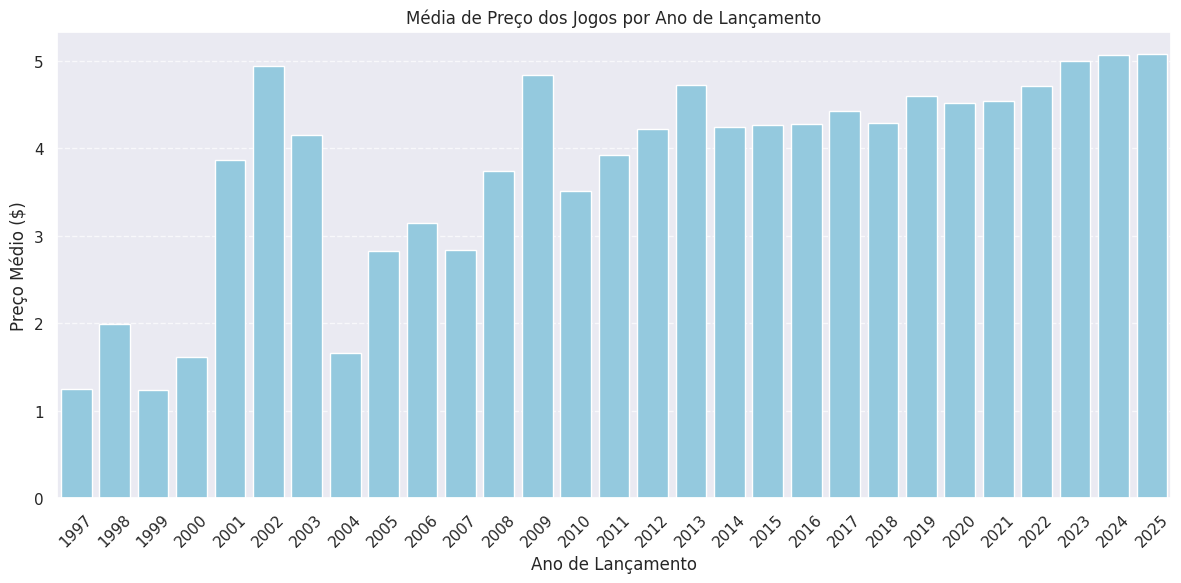

In [ ]:
# Extraindo o ano da coluna 'Release date'
df['Release year'] = df['Release date'].dt.year

# Agrupando por ano e calculando a média do preço
price_by_year = df.groupby('Release year')['Price'].mean().reset_index()

# Filtrando anos válidos para evitar ruídos de datas incorretas/futuras extremas se houver
price_by_year = price_by_year[(price_by_year['Release year'] >= 1997) & (price_by_year['Release year'] <= 2025)]

# Plotando o gráfico de barras para representar a média de preço ao longo dos anos
plt.figure(figsize=(12, 6))
sns.barplot(data=price_by_year, x='Release year', y='Price', color='skyblue')
plt.title('Média de Preço dos Jogos por Ano de Lançamento')
plt.xlabel('Ano de Lançamento')
plt.ylabel('Preço Médio ($)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

O gráfico acima mostra que o preço médio antes de 2012 era bastante incerto provavelmente pelo nível de maturidade da plataforma, isso indica que devemos desconsiderar os dados anteriores a este ano.

In [ ]:
# Filtrando o DataFrame para manter apenas lançamentos de 2012 em diante
df = df[df['Release year'] >= 2012]

# Exibindo o novo tamanho do dataset e as primeiras linhas
print(f"Novo tamanho do dataset: {len(df)} linhas")
display(df.head())

Novo tamanho do dataset: 124674 linhas


,AppID,Release date,Estimated owners,Required age,Price,Discount,Full audio languages,Categories,Genres,Tags,Platforms count,Release year
0,2539430,2023-08-01,0 - 0,0,0.00,0,0,NaN,NaN,NaN,1,2023
1,496350,2016-07-29,0 - 20000,0,5.24,65,0,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",1,2016
2,1034400,2019-05-06,0 - 20000,0,4.99,0,0,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",2,2019
3,3292190,2024-10-31,0 - 20000,0,8.99,0,1,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,1,2024
4,3631080,2025-04-24,0 - 20000,0,4.99,0,1,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,1,2025


In [ ]:
# Removendo registros onde a coluna 'Genres' está ausente ou é NaN
df = df.dropna(subset=['Genres'])

# Mostrando o novo tamanho do dataset após a limpeza
print(f"Tamanho do dataset após remover jogos sem gêneros: {len(df)} linhas")
display(df.head())

Tamanho do dataset após remover jogos sem gêneros: 116260 linhas


,AppID,Release date,Estimated owners,Required age,Price,Discount,Full audio languages,Categories,Genres,Tags,Platforms count,Release year
1,496350,2016-07-29,0 - 20000,0,5.24,65,0,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",1,2016
2,1034400,2019-05-06,0 - 20000,0,4.99,0,0,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",2,2019
3,3292190,2024-10-31,0 - 20000,0,8.99,0,1,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,1,2024
4,3631080,2025-04-24,0 - 20000,0,4.99,0,1,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,1,2025
5,1654170,2023-04-05,0 - 20000,0,13.99,0,2,"Single-player,Tracked Controller Support,VR On...","Action,Adventure",NaN,1,2023


In [ ]:
# Removendo registros onde a coluna 'Categories' está ausente ou é NaN
df = df.dropna(subset=['Categories'])

# Mostrando o novo tamanho do dataset após a limpeza
print(f"Tamanho do dataset após remover jogos sem Categorias: {len(df)} linhas")
display(df.head())

Tamanho do dataset após remover jogos sem Categorias: 115292 linhas


,AppID,Release date,Estimated owners,Required age,Price,Discount,Full audio languages,Categories,Genres,Tags,Platforms count,Release year
1,496350,2016-07-29,0 - 20000,0,5.24,65,0,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",1,2016
2,1034400,2019-05-06,0 - 20000,0,4.99,0,0,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",2,2019
3,3292190,2024-10-31,0 - 20000,0,8.99,0,1,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,1,2024
4,3631080,2025-04-24,0 - 20000,0,4.99,0,1,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,1,2025
5,1654170,2023-04-05,0 - 20000,0,13.99,0,2,"Single-player,Tracked Controller Support,VR On...","Action,Adventure",NaN,1,2023


In [ ]:
# Removendo registros onde o 'Price' é 0.0
df = df[df["Price"] > 0.0]

# Mostrando o novo tamanho do dataset após a limpeza
print(f"Tamanho do dataset após remover jogos sem preço: {len(df)} linhas")
display(df.head())

Tamanho do dataset após remover jogos sem preço: 97331 linhas


,AppID,Release date,Estimated owners,Required age,Price,Discount,Full audio languages,Categories,Genres,Tags,Platforms count,Release year
1,496350,2016-07-29,0 - 20000,0,5.24,65,0,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",1,2016
2,1034400,2019-05-06,0 - 20000,0,4.99,0,0,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",2,2019
3,3292190,2024-10-31,0 - 20000,0,8.99,0,1,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,1,2024
4,3631080,2025-04-24,0 - 20000,0,4.99,0,1,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,1,2025
5,1654170,2023-04-05,0 - 20000,0,13.99,0,2,"Single-player,Tracked Controller Support,VR On...","Action,Adventure",NaN,1,2023


In [ ]:
df['Price'] = df.apply(lambda row: row['Price'] / (1 - row['Discount'] / 100) if row['Discount'] > 0 and row['Discount'] < 100 else row['Price'], axis=1)

df = df.drop(columns=['Discount'])

display(df.head())

,AppID,Release date,Estimated owners,Required age,Price,Full audio languages,Categories,Genres,Tags,Platforms count,Release year
1,496350,2016-07-29,0 - 20000,0,14.971429,0,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",1,2016
2,1034400,2019-05-06,0 - 20000,0,4.990000,0,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",2,2019
3,3292190,2024-10-31,0 - 20000,0,8.990000,1,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,1,2024
4,3631080,2025-04-24,0 - 20000,0,4.990000,1,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,1,2025
5,1654170,2023-04-05,0 - 20000,0,13.990000,2,"Single-player,Tracked Controller Support,VR On...","Action,Adventure",NaN,1,2023


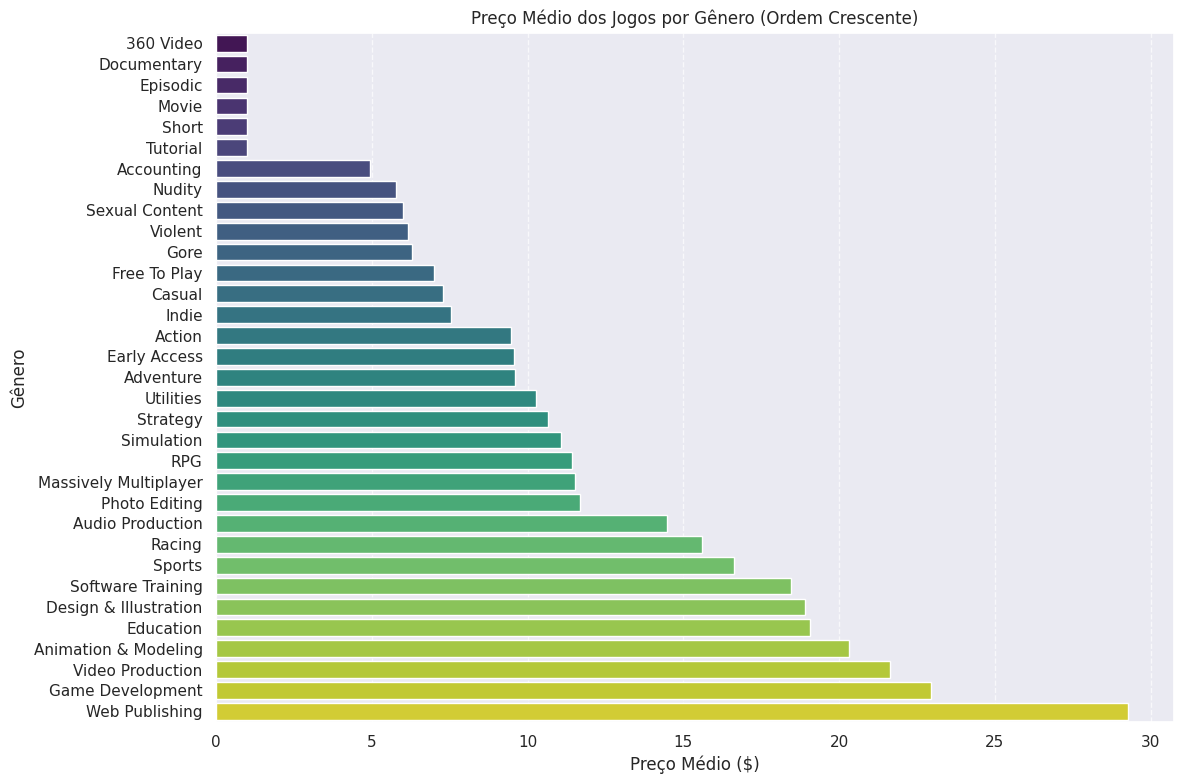

In [ ]:
# 1. Criar uma cópia do dataframe expandindo a coluna de gêneros
df_genres_exploded = df.copy()
df_genres_exploded['Genres'] = df_genres_exploded['Genres'].str.split(',')
df_genres_exploded = df_genres_exploded.explode('Genres')

# 2. Agrupar por gênero e calcular a média de preço
genre_avg_price = df_genres_exploded.groupby('Genres')['Price'].mean().reset_index()

# 3. Ordenar em ordem crescente pelo preço médio
genre_avg_price = genre_avg_price.sort_values(by='Price', ascending=True)

# 4. Plotar o gráfico de barras
plt.figure(figsize=(12, 8))
sns.barplot(data=genre_avg_price, x='Price', y='Genres', palette='viridis', hue='Genres', legend=False)
plt.title('Preço Médio dos Jogos por Gênero (Ordem Crescente)')
plt.xlabel('Preço Médio ($)')
plt.ylabel('Gênero')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

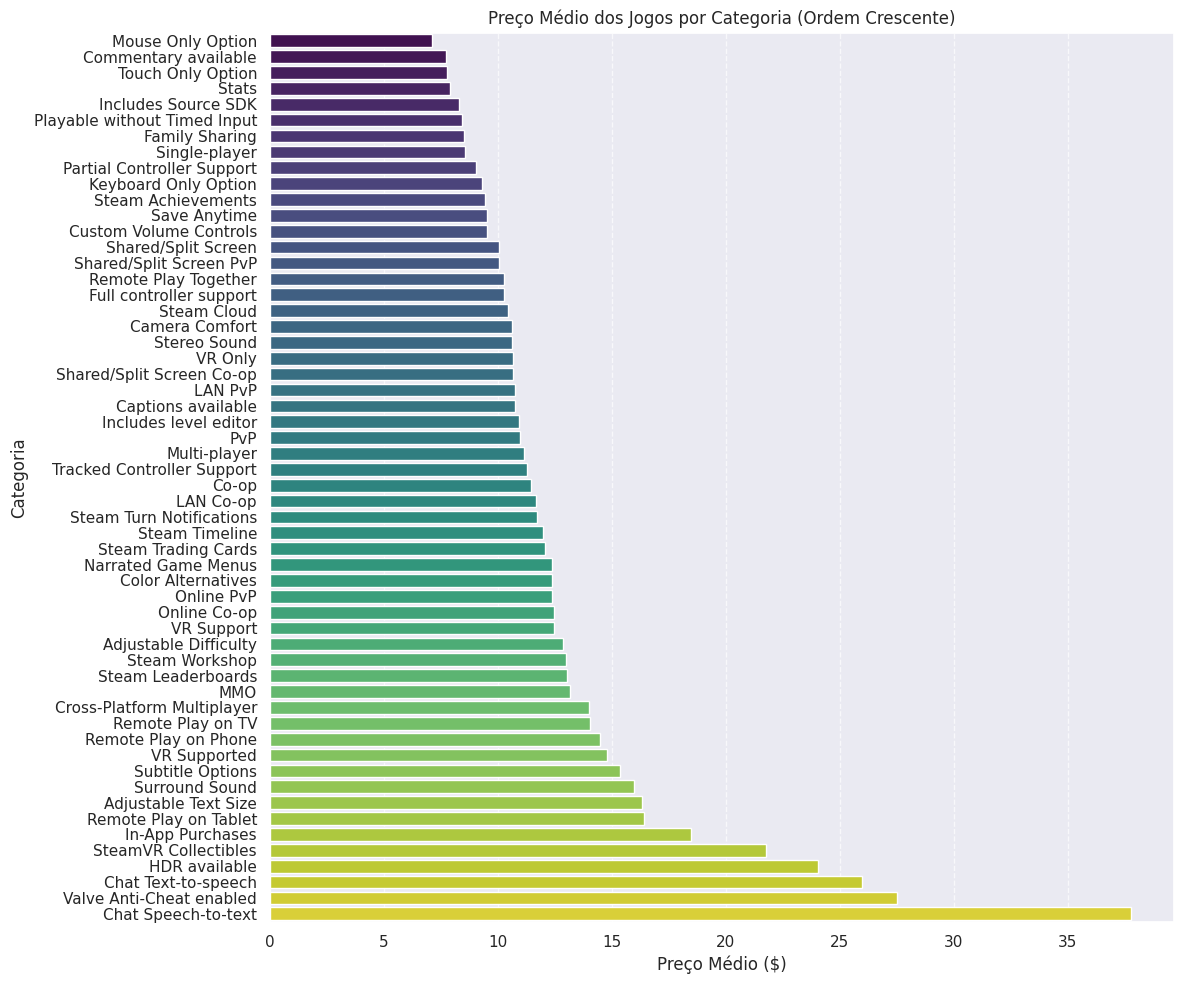

In [ ]:
# 1. Criar uma cópia do dataframe expandindo a coluna de categorias
df_categories_exploded = df.copy()
df_categories_exploded['Categories'] = df_categories_exploded['Categories'].str.split(',')
df_categories_exploded = df_categories_exploded.explode('Categories')

# 2. Agrupar por categoria e calcular a média de preço
categories_avg_price = df_categories_exploded.groupby('Categories')['Price'].mean().reset_index()

# 3. Ordenar em ordem crescente pelo preço médio
categories_avg_price = categories_avg_price.sort_values(by='Price', ascending=True)

# 4. Plotar o gráfico de barras
plt.figure(figsize=(12, 10))
sns.barplot(data=categories_avg_price, x='Price', y='Categories', palette='viridis', hue='Categories', legend=False)
plt.title('Preço Médio dos Jogos por Categoria (Ordem Crescente)')
plt.xlabel('Preço Médio ($)')
plt.ylabel('Categoria')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Visualização da Distribuição de Preço (Boxplot)

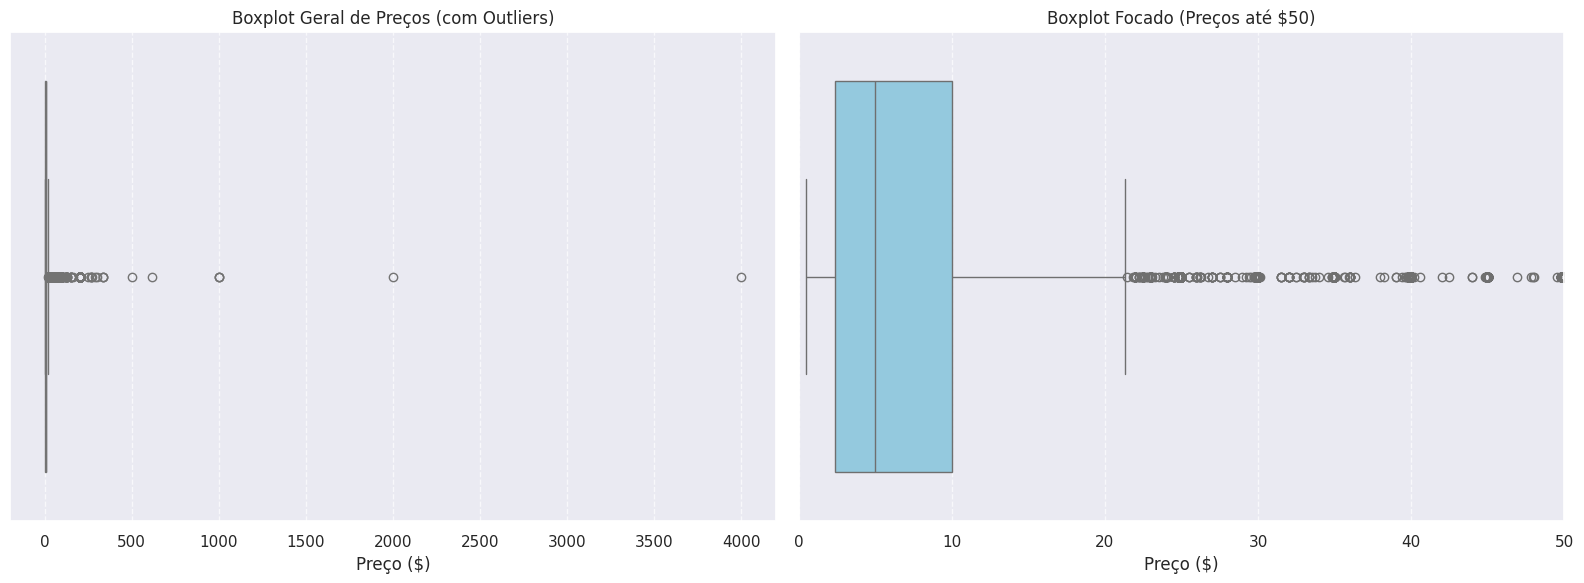

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Criando uma figura com dois subplots para melhor análise
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Boxplot completo (com todos os outliers)
sns.boxplot(data=df, x='Price', ax=axes[0], color='lightgreen')
axes[0].set_title('Boxplot Geral de Preços (com Outliers)')
axes[0].set_xlabel('Preço ($)')
axes[0].grid(axis='x', linestyle='--', alpha=0.7)

# 2. Boxplot focado (limitando o preço para visualizar melhor o intervalo interquartil)
# Vamos limitar para exibir jogos até $50 para detalhar a maior concentração de dados
sns.boxplot(data=df, x='Price', ax=axes[1], color='skyblue')
axes[1].set_xlim(0, 50)
axes[1].set_title('Boxplot Focado (Preços até $50)')
axes[1].set_xlabel('Preço ($)')
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Filtragem de Preços (Limitação entre $1 e $500)

In [ ]:
# Filtrando o DataFrame para manter apenas os preços entre $1 e $500
df = df[(df['Price'] >= 1.0) & (df['Price'] <= 500.0)]

# Exibindo o novo tamanho do dataset e estatísticas descritivas da coluna Price
print(f"Novo tamanho do dataset: {len(df)} linhas")
display(df['Price'].describe())

Novo tamanho do dataset: 85959 linhas


,Price
count,85959.000000
mean,9.490731
std,14.717465
min,1.000000
25%,2.990000
50%,5.980000
75%,9.990000
max,500.000000


### Criação da Coluna de Peso (`weight`) com base em `Estimated owners`

In [ ]:
import numpy as np

def calculate_estimated_owners_mean(val):
    if pd.isna(val) or not isinstance(val, str):
        return 0
    # Substitui caracteres especiais se houver e divide pelo hífen
    val_cleaned = val.replace(',', '').replace(' ', '')
    try:
        parts = val_cleaned.split('-')
        if len(parts) == 2:
            low = float(parts[0])
            high = float(parts[1])
            return (low + high) / 2
        return float(val_cleaned)
    except ValueError:
        return 0

# 1. Calcula o valor numérico médio estimado de proprietários
numeric_owners = df['Estimated owners'].apply(calculate_estimated_owners_mean)

# 2. Cria a coluna 'weight' aplicando o logaritmo (usamos log1p para lidar com zeros de forma segura)
df['weight'] = np.log1p(numeric_owners)

# Exibe o resultado com algumas colunas chave para validação
display(df[['Estimated owners', 'weight']].head(10))

,Estimated owners,weight
1,0 - 20000,9.210440
2,0 - 20000,9.210440
3,0 - 20000,9.210440
4,0 - 20000,9.210440
5,0 - 20000,9.210440
6,0 - 20000,9.210440
12,100000 - 200000,11.918397
13,0 - 20000,9.210440
14,0 - 20000,9.210440
16,0 - 20000,9.210440


### Preparação dos Dados e Treinamento da Árvore de Decisão com Pesos

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import numpy as np

# 1. Copiando os dados para preservação
df_model = df.copy()

# 2. Tratando a coluna 'Release date' (convertendo em dias desde a data mais antiga no dataset)
min_date = df_model['Release date'].min()
df_model['Days_since_release'] = (df_model['Release date'] - min_date).dt.days

# 3. Função auxiliar para vetorizar colunas textuais separadas por vírgula (Top 50 de cada)
def vetorizar_coluna(df, coluna, max_features=50):
    vectorizer = CountVectorizer(tokenizer=lambda x: [i.strip() for i in x.split(',')], max_features=max_features, lowercase=False)
    # Preenche NaNs com strings vazias
    temp_series = df[coluna].fillna("")
    X_vec = vectorizer.fit_transform(temp_series)
    vec_df = pd.DataFrame(X_vec.toarray(), columns=[f"{coluna}_{name}" for name in vectorizer.get_feature_names_out()], index=df.index)
    return vec_df

# Vetorizando categorias, gêneros e tags
categories_df = vetorizar_coluna(df_model, 'Categories', max_features=30)
genres_df = vetorizar_coluna(df_model, 'Genres', max_features=30)
tags_df = vetorizar_coluna(df_model, 'Tags', max_features=50)

# Juntando os recursos numéricos e os binarizados
features_num = df_model[['Required age', 'Full audio languages', 'Platforms count', 'Days_since_release']]
X = pd.concat([features_num, categories_df, genres_df, tags_df], axis=1)
y = df_model['Price']
weights = df_model['weight']

# 4. Divisão em Treino e Teste (incluindo os pesos)
X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, weights, test_size=0.2, random_state=42
)

# 5. Criando e treinando a Árvore de Decisão usando os pesos (sample_weight)
model = DecisionTreeRegressor(max_depth=12, random_state=42)
model.fit(X_train, y_train, sample_weight=w_train)

# 6. Avaliação do Modelo
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred, sample_weight=w_test)
r2 = r2_score(y_test, y_pred, sample_weight=w_test)

print(f"Resultados do Modelo (Ponderados por 'weight'):")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R² Score: {r2:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


Resultados do Modelo (Ponderados por 'weight'):
Mean Squared Error (MSE): 185.3095
R² Score: -0.1070


### Função para Predição de Preço de Novos Jogos
Esta função realiza o processamento dos dados do novo jogo de forma idêntica à do treinamento e utiliza a árvore de decisão para estimar o preço.

In [ ]:
def prever_preco_jogo(
    release_date_str,
    required_age,
    full_audio_languages_count,
    platforms_count,
    categories_str,
    genres_str,
    tags_str
):
    # 1. Obter a lista de colunas que o modelo usou no treinamento
    colunas_modelo = X.columns

    # 2. Inicializar um dicionário com 0 para todos os recursos do modelo
    input_data = {col: [0] for col in colunas_modelo}

    # 3. Preencher os valores numéricos básicos
    input_data['Required age'] = [required_age]
    input_data['Full audio languages'] = [full_audio_languages_count]
    input_data['Platforms count'] = [platforms_count]

    # 4. Tratar a data de lançamento para obter dias desde o lançamento mínimo
    data_convertida = pd.to_datetime(release_date_str)
    dias_desde_min = (data_convertida - min_date).days
    input_data['Days_since_release'] = [dias_desde_min]

    # 5. Processar as colunas de texto (categorias, gêneros e tags)
    # Função interna para ativar a presença dos termos corretos no input_data
    def ativar_atributos(texto, prefixo):
        if pd.notna(texto) and isinstance(texto, str):
            itens = [item.strip() for item in texto.split(',')]
            for item in itens:
                col_name = f"{prefixo}_{item}"
                if col_name in input_data:
                    input_data[col_name] = [1]

    ativar_atributos(categories_str, 'Categories')
    ativar_atributos(genres_str, 'Genres')
    ativar_atributos(tags_str, 'Tags')

    # 6. Criar o DataFrame de entrada com a ordem exata de colunas
    df_input = pd.DataFrame(input_data)[colunas_modelo]

    # 7. Realizar a predição com o modelo treinado
    preco_estimado = model.predict(df_input)[0]
    return round(preco_estimado, 2)

# Exemplo de demonstração de uso
preco_demonstracao = prever_preco_jogo(
    release_date_str='2025-06-01',
    required_age=12,
    full_audio_languages_count=2,
    platforms_count=3,
    categories_str='Single-player,Multi-player,Steam Achievements,Steam Cloud',
    genres_str='Action,Adventure,RPG',
    tags_str='RPG,Open World,Action,Adventure'
)

print(f"Preço estimado para o jogo de demonstração: ${preco_demonstracao}")

Preço estimado para o jogo de demonstração: $29.11
